Preprocess the raw data, with outputs:
- the random phase offset
- when does the ref signal end
- when does the loc signal begin

(1.3720188670688205, 0.020277449312815738)

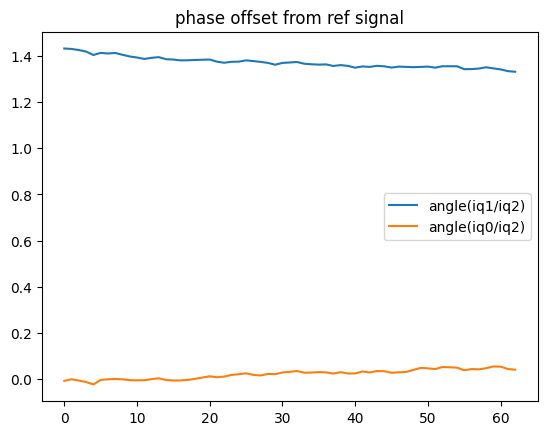

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from read_raw_data import read_dat_file 
# from AoA_formula import calc_AoA

# iq0_path = '/home/ishani/LeoPNT/USRP_data/12_27/time_20_47_freq_11_325G_bw_2.0M_1703723111.7046282_inrx0.dat'
iq0_path = '/home/ishani/LeoPNT/USRP_data/12_20/time_23_9_freq_11_0G_bw_2.0M_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')

is_ref = True
len_frame = int(0.1*2e6)
iq0_first_frame = read_dat_file(iq0_path, len_frame, 0)
pw_ref = np.mean(np.abs(iq0_first_frame)**2)
start_idx = len_frame
ref_frame_cnt = 0

while is_ref:
    iq0 =  read_dat_file(iq0_path, len_frame, start_idx)
    start_idx += len_frame
    ref_frame_cnt += 1
    avg_pw = np.mean(np.abs(iq0)**2)
    if avg_pw < 0.6*pw_ref:
        is_ref = False
        noise_idx = start_idx+len_frame

ref_frame_cnt -= 5
start_idx = len_frame
phase_offset_12, phase_offset_02 = np.zeros(ref_frame_cnt), np.zeros(ref_frame_cnt)
for i in range(ref_frame_cnt):
    iq0 = read_dat_file(iq0_path, len_frame, start_idx)
    iq1 = read_dat_file(iq1_path, len_frame, start_idx)
    iq2 = read_dat_file(iq2_path, len_frame, start_idx)
    start_idx += len_frame
    phase_offset_12[i] = np.mean(np.unwrap(np.angle(iq1/iq2)))
    phase_offset_02[i] = np.mean(np.unwrap(np.angle(iq0/iq2)))

# avoid jump
if np.max(phase_offset_02) - np.min(phase_offset_02) > 2*np.pi:
    phase_offset_02[phase_offset_02 < 0] += 2*np.pi
    
plt.plot(phase_offset_12, label='angle(iq1/iq2)')
plt.plot(phase_offset_02, label='angle(iq0/iq2)')
plt.title('phase offset from ref signal')
plt.legend()
phase_offset_12_mean = np.mean(phase_offset_12)
phase_offset_02_mean = np.mean(phase_offset_02)
phase_offset_12_mean, phase_offset_02_mean

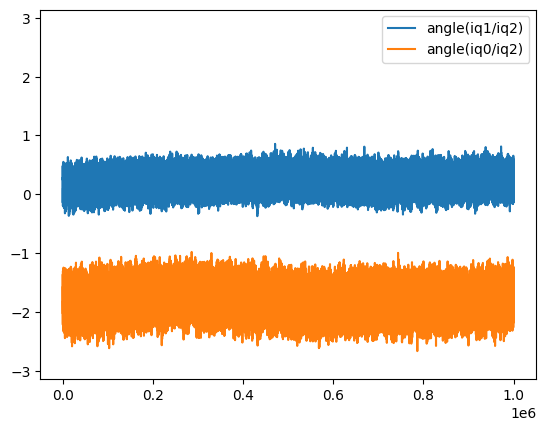

In [2]:
iq0 =  read_dat_file(iq0_path, len_frame, noise_idx)
pw_noise = np.mean(np.abs(iq0)**2)
is_noise = True
len_frame = int(.1*2e6)
start_idx = noise_idx

while is_noise:
    iq0 =  read_dat_file(iq0_path, len_frame, start_idx)
    start_idx += len_frame
    avg_pw = np.mean(np.abs(iq0)**2)
    if avg_pw > 20*pw_noise:
        is_noise = False
        sig_idx = start_idx+len_frame*10
sig_idx += len_frame*54
len_frame = int(.5*2e6)
iq0 = read_dat_file(iq0_path, len_frame, sig_idx)
iq1 = read_dat_file(iq1_path, len_frame, sig_idx)
iq2 = read_dat_file(iq2_path, len_frame, sig_idx)
plt.plot(np.unwrap(np.angle(iq1/iq2*np.exp(-1j*phase_offset_12_mean))), label='angle(iq1/iq2)')
plt.plot(np.unwrap(np.angle(iq0/iq2*np.exp(-1j*phase_offset_02_mean))), label='angle(iq0/iq2)')
plt.ylim([-np.pi, np.pi])
plt.legend()

In [3]:
def calc_AoA(iq0, iq1, iq2, d_02, d_12, lam, phase_offset_02, phase_offset_12):
    """
    iq2------iq1
    |
    |
    |
    iq0

    to reuse the previous code, here 1 means direction 0-2, 2 means direction 1-2
    """
    phi_bound_1 = d_02/lam*2*np.pi
    phi_bound_2 = d_12/lam*2*np.pi
    num_ambiguity_1 = np.ceil(phi_bound_1/(np.pi)).astype(int)
    num_ambiguity_2 = np.ceil(phi_bound_2/(np.pi)).astype(int)
    phi_bias_1 = np.zeros((num_ambiguity_1, 1))
    phi_bias_2 = np.zeros((num_ambiguity_2, 1))
    pattern_1 = np.unwrap(np.angle(iq0/iq2*np.exp(-1j*phase_offset_02)))
    pattern_2 = np.unwrap(np.angle(iq1/iq2*np.exp(-1j*phase_offset_12)))
    d_1, d_2 = d_02, d_12

    # calculate all possible delta_phis
    for i in range(num_ambiguity_1):
        phi_bias_1[i] = 2*np.pi*(i-num_ambiguity_1//2)
    if np.mean(pattern_1+phi_bias_1[0]) < -phi_bound_1:
        phi_bias_1 += 2*np.pi
    for i in range(num_ambiguity_2):
        phi_bias_2[i] = 2*np.pi*(i-num_ambiguity_2//2)
    if np.mean(pattern_2+phi_bias_2[0]) < -phi_bound_2:
        phi_bias_2 += 2*np.pi
        
    # plt.figure()
    # for i in range(num_ambiguity_1):
    #     plt.plot(pattern_1 + phi_bias_1[i])
    # plt.hlines(-phi_bound_1, 0, len(iq0)-1, linestyles='dashed', colors='brown', label='lower bound')
    # plt.hlines(phi_bound_1, 0, len(iq0)-1, linestyles='dashed', colors='brown', label='lower bound')
    # plt.legend()
    # plt.title('All possible phase difference - 1')
    # plt.show()
    # plt.figure()
    # for i in range(num_ambiguity_2):
    #     plt.plot(pattern_2 + phi_bias_2[i])
    # plt.hlines(-phi_bound_2, 0, len(iq0)-1, linestyles='dashed', colors='brown', label='lower bound')
    # plt.hlines(phi_bound_2, 0, len(iq0)-1, linestyles='dashed', colors='brown', label='lower bound')
    # plt.legend()
    # plt.title('All possible phase difference - 2')
    # plt.show()

    # calculate AoA
    # first check which del_phi exceeds the bounds, exclude those
    for i in range(num_ambiguity_1):
        del_phi_1_i = pattern_1 + phi_bias_1[i]
        if np.max(del_phi_1_i) > phi_bound_1 or np.min(del_phi_1_i) < -phi_bound_1:
            phi_bias_1[i] = np.nan
    for i in range(num_ambiguity_2):
        del_phi_2_i = pattern_2 + phi_bias_2[i]
        if np.max(del_phi_2_i) > phi_bound_2 or np.min(del_phi_2_i) < -phi_bound_2:
            phi_bias_2[i] = np.nan
    phi_bias_1 = phi_bias_1[~np.isnan(phi_bias_1)]
    phi_bias_2 = phi_bias_2[~np.isnan(phi_bias_2)]
    num_ambiguity_2d = len(phi_bias_1) * len(phi_bias_2)
    print('Number of del_phi_1 ambiguities: '+str(len(phi_bias_1)))
    print('Number of del_phi_2 ambiguities: '+str(len(phi_bias_2)))

    # then do the formula based AoA estimation
    phi, az, el = np.zeros((num_ambiguity_2d, len(iq0))), np.zeros((num_ambiguity_2d, len(iq0))), np.zeros((num_ambiguity_2d, len(iq0)))
    for i in range(len(phi_bias_1)):
        for j in range(len(phi_bias_2)):
            del_phi_1_i = pattern_1 + phi_bias_1[i]
            del_phi_2_j = pattern_2 + phi_bias_2[j]
            phi_ = np.arctan2(-del_phi_2_j/d_2, -del_phi_1_i/d_1)
            phi_ = np.mod(phi_, 2*np.pi)
            az_ = 2*np.pi-phi_
            # elevation
            el_ = np.arccos(-del_phi_1_i*lam/(2*np.pi*d_1*np.cos(az_)))
            az[i*len(phi_bias_2)+j, :] = az_
            el[i*len(phi_bias_2)+j, :] = el_
            
    return az, el

In [4]:
d_02, d_12 = 0.13, 0.2
c = 3e8
fc = 11e9
lam = c/fc
az, el = calc_AoA(iq0, iq1, iq2, d_02, d_12, lam, phase_offset_02_mean, phase_offset_12_mean)

Number of del_phi_1 ambiguities: 9
Number of del_phi_2 ambiguities: 15


/tmp/ipykernel_29687/1135743953.py:74: RuntimeWarning: invalid value encountered in arccos
  el_ = np.arccos(-del_phi_1_i*lam/(2*np.pi*d_1*np.cos(az_)))


In [9]:
# save el and az to .mat file
import scipy.io as sio
sio.savemat('AoA.mat', {'az': az[:,20000:40000], 'el': el[:,20000:40000]})

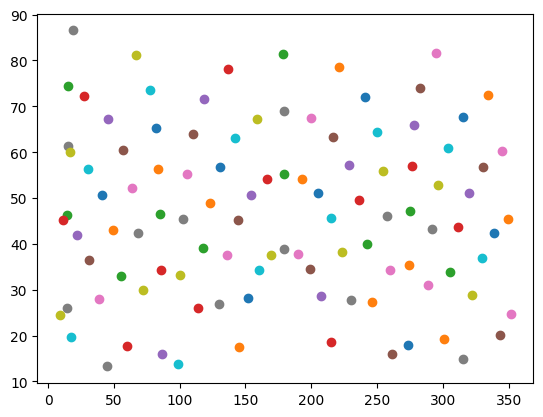

In [13]:
plt.figure()
for i in range(el.shape[0]):
    plt.scatter(np.mean(np.degrees(az[i, :])), np.mean(np.degrees(el[i, :])))